imports and global vars

In [44]:
import json, re
from collections import Counter
import numpy as np
import nltk
import os

import torch
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.nn.utils import clip_grad_norm_
from torch.utils import data
from torch.utils.data import DataLoader, Dataset

import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../Data/data/en-US.jsonl"
GLOVE_PATH = "../Data/glove/glove.6B.300d.txt"
SLOT_REGEX = re.compile(r"\[([^\[\]:]+)\s*:\s*([^\[\]]+)\]")
UNK_TOKEN = "<UNK>"
PAD_TOKEN = "<PAD>"
HIDDEN_SIZE = 128
NUM_EPOCHS = 100
BATCH_SIZE = 50
LEARNING_RATE = 0.01
EMBEDDING_DIM = 300  # glove embedding are usually 50,100,200,300
SAVE_DIR = "../Results/"

load dataset functions

In [45]:
def parse_slots(annot_utt):
    # get list of (slot_type, slot_span) from annot_utt
    # turns the [color_type : pink] into ("color_type", "pink")
    return [(t.strip(), s.strip()) for t, s in SLOT_REGEX.findall(annot_utt)]

def load_massive(path=DATA_PATH):
    splits = {"train": [], "dev": [], "test": []}
    with open(path, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            r = json.loads(line)
            splits[r["partition"]].append({
                "id": r["id"],
                "scenario": r["scenario"],
                "intent": r["intent"],
                "utt": r["utt"],
                "annot_utt": r["annot_utt"],
                "slots": parse_slots(r["annot_utt"]),  
            })
    return splits

split the dataset

In [46]:
splits = load_massive()
expected = {"train": 11514, "dev": 2033, "test": 2974}
for k, n in expected.items():
    print(f"{k}: {len(splits[k])}")
    assert len(splits[k]) == n
assert sum(len(v) for v in splits.values()) == 16521

intents = sorted({r["intent"] for v in splits.values() for r in v})
slotTypes = sorted({t for v in splits.values() for r in v for t, _ in r["slots"]})
print("intents:", len(intents), "| slot types:", len(slotTypes))
print(splits["train"][1])

train: 11514
dev: 2033
test: 2974
intents: 60 | slot types: 55
{'id': '2', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'set an alarm for two hours from now', 'annot_utt': 'set an alarm for [time : two hours from now]', 'slots': [('time', 'two hours from now')]}


preprocessing data

going with BIOES tagging for the parts of the sentence

In [47]:
def annot_to_bioes(annot_utt):
    """Convert annotated text into tokens and BIOES tags."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell

    tokens = []
    tags = []
    position = 0

    # Process each annotated slot, such as [time : five am]
    for match in SLOT_REGEX.finditer(annot_utt):

        # Words outside a slot are tagged as O
        outsideText = annot_utt[position:match.start()]

        for word in outsideText.split():
            tokens.append(word)
            tags.append("O")

        slotType = match.group(1).strip()
        words = match.group(2).split()

        # Assign BIOES tag for each word 
        for i, word in enumerate(words):
            if len(words) == 1:
                tag = f"S-{slotType}"
            elif i == 0:
                tag = f"B-{slotType}"
            elif i == len(words) - 1:
                tag = f"E-{slotType}"
            else:
                tag = f"I-{slotType}"

            tokens.append(word)
            tags.append(tag)

        position = match.end()

    # Process any remaining words after the last slot
    for word in annot_utt[position:].split():
        tokens.append(word)
        tags.append("O")

    return tokens, tags


def build_tag_vocab(records):

    slotTypes = sorted({
        slotType
        for record in records
        for slotType, _ in record["slots"]
    })

    tags = ["O"]

    for slotType in slotTypes:
        for prefix in ("B", "I", "E", "S"):
            tags.append(f"{prefix}-{slotType}")

    tagToId = {tag: i for i, tag in enumerate(tags)}

    return tags, tagToId


Decode the BIOES tags into (slot_type, slot_span)

In [48]:
def decode_bioes(tokens, tags):
    """Convert BIOES tags into a list of (slotType, slotSpan) pairs."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell
    
    spans = []
    currentType = None
    currentTokens = []

    def closeSpan():
        nonlocal currentType, currentTokens

        if currentType is not None:
            slotText = " ".join(currentTokens)
            spans.append((currentType, slotText))

        currentType = None
        currentTokens = []

    for token, tag in zip(tokens, tags):

        if tag == "O":
            closeSpan()
            continue

        prefix, slotType = tag.split("-", 1)

        if prefix == "B":
            closeSpan()
            currentType = slotType
            currentTokens = [token]

        elif prefix == "I":
            if currentType == slotType:
                currentTokens.append(token)
            else:
                closeSpan()
                currentType = slotType
                currentTokens = [token]

        elif prefix == "E":
            if currentType == slotType:
                currentTokens.append(token)
                closeSpan()
            else:
                closeSpan()
                spans.append((slotType, token))

        elif prefix == "S":
            closeSpan()
            spans.append((slotType, token))

        else:
            closeSpan()

    # Include any unfinished span at the end
    closeSpan()

    return spans

Evaluation functions

In [49]:
def eval_intent_accuracy(actual, predicted):
    """Calculate the percentage of correctly predicted intents."""

    assert len(actual) == len(predicted)

    correctCount = sum(
        gold == pred
        for gold, pred in zip(actual, predicted)
    )

    return 100.0 * correctCount / len(actual)

def eval_macro_f1(actual, predicted):
    """Calculate micro F1 for slot types and spans across all utterances."""

    assert len(actual) == len(predicted)

    truePositives = 0
    falsePositives = 0
    falseNegatives = 0

    for act, pred in zip(actual, predicted):
        actualCount = Counter(act)
        predCount= Counter(pred)

        matchedCount = sum((actualCount & predCount).values())

        truePositives += matchedCount
        falsePositives += sum(predCount.values()) - matchedCount
        falseNegatives += sum(actualCount.values()) - matchedCount

    denominator = (
        2 * truePositives
        + falsePositives
        + falseNegatives
    )

    if denominator == 0:
        return 0.0

    return 100.0 * 2 * truePositives / denominator

def evaluate(goldIntents, predIntents, goldSlots, predSlots):
    """Calculate and return intent accuracy and slot F1."""

    intentAcc = round(eval_intent_accuracy(goldIntents, predIntents), 2)

    slotF1 = round(eval_macro_f1(goldSlots, predSlots), 2)

    return {
        "intent_acc": intentAcc,
        "slot_f1": slotF1,
    }

---
# Stage 1: BiLSTM baseline (no attention)

**Pipeline**

| Part | Description |
|---|---|
| Input | the whitespace-tokenised `utt` only (lower-cased for the vocabulary lookup) |
| Embedding | 100-d GloVe vectors (word vectors are the only pretrained component allowed), fine-tuned during training |
| Encoder | 2-layer **bidirectional LSTM**, hidden size 128 per direction, dropout 0.3. No attention anywhere |
| Task 1 (intent) | final forward + backward hidden states of the top layer, concatenated (256-d), then a linear layer to 60 intents |
| Task 2 (slots) | per-token BiLSTM outputs (256-d), then a linear layer to 221 BIOES tags (`O` + 4 x 55 slot types) |
| Loss | `CE(intent) + CE(slot tags)` with padding ignored, i.e. joint multi-task training |
| Optimizer | Adam (lr = `LEARNING_RATE`), gradient-norm clipping at 5, `ReduceLROnPlateau` on the validation score |
| Regularisation | dropout on embeddings / LSTM / outputs, plus word-dropout (random tokens replaced by `<UNK>` during training) so that `<UNK>` is learned |
| Checkpoint | best epoch by validation combined score = (intent accuracy + slot micro-F1) / 2 |

Vocabulary is built from the **training split only**. At inference, slot tags are decoded back into `(slot_type, slot_span)` pairs with `decode_bioes`.

In [50]:
import time, random
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_packed_sequence
from torch.optim.lr_scheduler import ReduceLROnPlateau

SEED = 6769
NUM_LAYERS = 2
DROPOUT = 0.3
WORD_DROPOUT = 0.1
GRAD_CLIP = 5.0
PATIENCE = 15
IGNORE_INDEX = -100
BASELINE_CKPT = os.path.join(SAVE_DIR, "baseline_bilstm_best.pt")

os.makedirs(SAVE_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


### Build vocabularies and encode the data

* word vocabulary: **train split only** (lower-cased), plus `<PAD>`=0 and `<UNK>`=1
* intent vocabulary: the 60 intent labels
* tag vocabulary: `O` + `{B,I,E,S}-<slot_type>` for the 55 slot types (`build_tag_vocab`)

In [51]:
def get_tokens_and_tags(record):
    """Model input = utt tokens. Tags come from annot_utt (BIOES). If the annotation tokenisation ever
    differs from utt.split(), fall back to the annotation's own tokens (same words, so no label leakage)."""
    uttTokens = record["utt"].split()
    annotTokens, bioesTags = annot_to_bioes(record["annot_utt"])

    if len(uttTokens) == len(annotTokens):
        return uttTokens, bioesTags, False
    return annotTokens, bioesTags, True

def normalise_slots(slots):
    return [(t, " ".join(s.split())) for t, s in slots]

# handle vocab for words, intents, and tags
allRecords = [record for split in splits.values() for record in split]
tagList, tagToId = build_tag_vocab(allRecords)
idToTag = {tagId: tag for tag, tagId in tagToId.items()}
assert len(tagList) == 1 + 4 * len(slotTypes)

intentToId = {intent: i for i, intent in enumerate(intents)}
idToIntent = {i: intent for intent, i in intentToId.items()}

# word vocab (training split only, lower-cased)
wordCounter = Counter()
for record in splits["train"]:
    tokens, _, _ = get_tokens_and_tags(record)
    wordCounter.update(word.lower() for word in tokens)

idToWord = [PAD_TOKEN, UNK_TOKEN] + [word for word, _ in wordCounter.most_common()]
wordToId = {word: i for i, word in enumerate(idToWord)}
PAD_ID, UNK_ID = wordToId[PAD_TOKEN], wordToId[UNK_TOKEN]

print(f"word vocab: {len(wordToId)} | intents: {len(intentToId)} | tags: {len(tagToId)}")

# encode each split
def encode_split(records):
    """Turn raw records into model-ready examples. Returns (examples, numMismatches)."""
    examples = []
    numMismatches = 0

    for record in records:
        tokens, bioesTags, usedAnnotTokens = get_tokens_and_tags(record)
        numMismatches += usedAnnotTokens

        examples.append({
            "tokens": tokens,
            "ids": torch.tensor([wordToId.get(word.lower(), UNK_ID) for word in tokens], dtype=torch.long),
            "tags": torch.tensor([tagToId[tag] for tag in bioesTags], dtype=torch.long),
            "intent": intentToId[record["intent"]],
            "gold_slots": normalise_slots(record["slots"]),
        })

    return examples, numMismatches


encoded = {}
for splitName in ("train", "dev", "test"):
    encoded[splitName], numMismatches = encode_split(splits[splitName])

    isUnk = [
        wordToId.get(word.lower(), UNK_ID) == UNK_ID
        for example in encoded[splitName]
        for word in example["tokens"]
    ]
    oovRate = np.mean(isUnk) * 100
    print(f"{splitName}: {len(encoded[splitName])} examples | "
          f"utt/annot tokenisation mismatches: {numMismatches} | OOV token rate: {oovRate:.2f}%")

seqLengths = [len(example["tokens"]) for example in encoded["train"]]
print("train sequence length: mean %.1f, max %d" % (np.mean(seqLengths), max(seqLengths)))

word vocab: 5304 | intents: 60 | tags: 221
train: 11514 examples | utt/annot tokenisation mismatches: 0 | OOV token rate: 0.00%
dev: 2033 examples | utt/annot tokenisation mismatches: 0 | OOV token rate: 3.32%
test: 2974 examples | utt/annot tokenisation mismatches: 0 | OOV token rate: 3.51%
train sequence length: mean 6.9, max 35


In [52]:
# check that the encode-decode cycle matches with the gold slots
numBad = 0
for example in encoded["train"]:
    tagSeq = [idToTag[tagId.item()] for tagId in example["tags"]]
    decodedSlots = decode_bioes(example["tokens"], tagSeq)
    numBad += (decodedSlots != example["gold_slots"])

print("train examples where decode(encode(annot)) != gold slots:", numBad)
assert numBad == 0

train examples where decode(encode(annot)) != gold slots: 0


In [53]:
class NLUDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, i):
        return self.examples[i]

def collate_fn(batch):
    ids = pad_sequence([b["ids"] for b in batch], batch_first=True, padding_value=PAD_ID)
    tags = pad_sequence([b["tags"] for b in batch], batch_first=True, padding_value=IGNORE_INDEX)
    lengths = torch.tensor([len(b["ids"]) for b in batch], dtype=torch.long)
    intents_ = torch.tensor([b["intent"] for b in batch], dtype=torch.long)
    return ids, tags, lengths, intents_, [b["tokens"] for b in batch]

g = torch.Generator()
g.manual_seed(SEED)
trainLoader = DataLoader(NLUDataset(encoded["train"]), batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate_fn, generator=g)
devLoader   = DataLoader(NLUDataset(encoded["dev"]),   batch_size=256, shuffle=False, collate_fn=collate_fn)
testLoader  = DataLoader(NLUDataset(encoded["test"]),  batch_size=256, shuffle=False, collate_fn=collate_fn)
print("batches/epoch:", len(trainLoader))

batches/epoch: 231


### Word embeddings (GloVe)

Only vocabulary words that appear in the **training** split are looked up in GloVe. Words not found in GloVe get a small random vector, and `<PAD>` is all zeros.
If `GLOVE_PATH` does not exist the notebook falls back to random initialisation and prints a warning, so make sure the printed coverage line below shows GloVe was actually loaded for the final run.

In [54]:
def load_glove_matrix(path, wordToId, dim):
    rng = np.random.RandomState(SEED)
    matrix = rng.normal(0, 0.3, size=(len(wordToId), dim)).astype(np.float32)
    matrix[PAD_ID] = 0.0
    
    if path is None or not os.path.exists(path):
        print(f"WARNING: GloVe file not found at {path}. Using random embeddings.")
        return torch.from_numpy(matrix), 0
    numFound = 0
    
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            w = parts[0]

            if w in wordToId and w not in (PAD_TOKEN, UNK_TOKEN) and len(parts) == dim + 1:
                matrix[wordToId[w]] = np.asarray(parts[1:], dtype=np.float32)
                numFound += 1
    
    coveragePct = 100 * numFound / len(wordToId)
    print(f"GloVe coverage: {numFound}/{len(wordToId)} vocab words ({coveragePct:.1f}%)")
    return torch.from_numpy(matrix), numFound

embedding_matrix, glove_found = load_glove_matrix(GLOVE_PATH, wordToId, EMBEDDING_DIM)

GloVe coverage: 4918/5304 vocab words (92.7%)


### Model: joint BiLSTM for intent classification + slot filling

`pack_padded_sequence` is used so the final hidden states (for the intent head) come from the true last token of every utterance, not from padding.

In [55]:
class BiLSTMJoint(nn.Module):
    def __init__(self, vocabSize, embDim, hiddenSize, numLayers, numIntents, numTags,
                 dropout, padIdx, pretrained=None):
        super().__init__()
        self.embedding = nn.Embedding(vocabSize, embDim, padding_idx=padIdx)
        if pretrained is not None:
            self.embedding.weight.data.copy_(pretrained)

        self.embDropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embDim, hiddenSize, num_layers=numLayers, batch_first=True,
                            bidirectional=True, dropout=dropout if numLayers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)

        self.intentHead = nn.Linear(2 * hiddenSize, numIntents)
        self.slotHead = nn.Linear(2 * hiddenSize, numTags)
    
    def forward(self, ids, lengths):
        embedded = self.embDropout(self.embedding(ids))

        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packedOut, (finalHidden, _) = self.lstm(packed)
        seqOut, _ = pad_packed_sequence(packedOut, batch_first=True, total_length=ids.size(1))

        # top layer's final forward + backward hidden states
        sentenceRepr = torch.cat([finalHidden[-2], finalHidden[-1]], dim=-1)

        intentLogits = self.intentHead(self.dropout(sentenceRepr))
        slotLogits = self.slotHead(self.dropout(seqOut))
        return intentLogits, slotLogits

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def build_baseline():
    return BiLSTMJoint(len(wordToId), 
                       EMBEDDING_DIM, 
                       HIDDEN_SIZE, 
                       NUM_LAYERS, 
                       len(intentToId),
                       len(tagToId), 
                       DROPOUT, 
                       PAD_ID, 
                       pretrained=embedding_matrix
                       ).to(device)

set_seed()
baselineModel = build_baseline()
print(baselineModel)
baseTotal, baseTrainable = count_params(baselineModel)
print(f"\ntotal parameters: {baseTotal:,} | trainable: {baseTrainable:,}")

BiLSTMJoint(
  (embedding): Embedding(5304, 300, padding_idx=0)
  (embDropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (intentHead): Linear(in_features=256, out_features=60, bias=True)
  (slotHead): Linear(in_features=256, out_features=221, bias=True)
)

total parameters: 2,499,001 | trainable: 2,499,001


### Training / prediction utilities

`predict()` runs a split through the model (dropout off) and returns the losses, predicted intents and predicted `(slot_type, slot_span)` pairs. The scoring uses the shared `evaluate()` defined earlier. These helpers take the model as an argument so they can be reused unchanged in Stage 2.

In [56]:
def compute_losses(intentLogits, slotLogits, intentIds, tags):
    intentLoss = F.cross_entropy(intentLogits, intentIds)
    slotLoss = F.cross_entropy(
        slotLogits.reshape(-1, slotLogits.size(-1)),
        tags.reshape(-1),
        ignore_index=IGNORE_INDEX,
    )
    return intentLoss + slotLoss, intentLoss, slotLoss

def move_batch_to_device(ids, tags, lengths, intentIds):
    # send the batch tensors to the cpu for processing
    return ids.to(device), tags.to(device), lengths.to(device), intentIds.to(device)

@torch.no_grad()
def predict(model, loader):
    """Run a split through the model with dropout off.

    Returns a dict with the mean losses ("loss", "intent_loss", "slot_loss") and the predictions
    ("pred_intents", "pred_slots", "pred_tags").
    """
    model.eval()
    lossTotals = {"loss": 0.0, "intent_loss": 0.0, "slot_loss": 0.0}
    numBatches = 0
    predIntents, predSlots, predTags = [], [], []

    for ids, tags, lengths, intentIds, tokens in loader:
        ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)

        intentLogits, slotLogits = model(ids, lengths)
        loss, intentLoss, slotLoss = compute_losses(intentLogits, slotLogits, intentIds, tags)

        lossTotals["loss"] += loss.item()
        lossTotals["intent_loss"] += intentLoss.item()
        lossTotals["slot_loss"] += slotLoss.item()
        numBatches += 1

        # intents: one argmax per utterance
        predIntents += [idToIntent[intentId] for intentId in intentLogits.argmax(-1).tolist()]

        # slots: argmax per token, trimmed to the real length, then decoded into (type, span) pairs
        tagIdRows = slotLogits.argmax(-1).cpu().tolist()
        for utteranceTokens, tagIds in zip(tokens, tagIdRows):
            tagSeq = [idToTag[tagId] for tagId in tagIds[:len(utteranceTokens)]]
            predTags.append(tagSeq)
            predSlots.append(decode_bioes(utteranceTokens, tagSeq))

    output = {key: total / numBatches for key, total in lossTotals.items()}
    output.update(pred_intents=predIntents, pred_slots=predSlots, pred_tags=predTags)
    return output

def score_split(out, records_encoded):
    gold_intents = [idToIntent[e["intent"]] for e in records_encoded]
    gold_slots = [e["gold_slots"] for e in records_encoded]
    m = evaluate(gold_intents, out["pred_intents"], gold_slots, out["pred_slots"])
    m["combined"] = round((m["intent_acc"] + m["slot_f1"]) / 2, 2)
    return m

def apply_word_dropout(ids):
    """Randomly replace non-padding tokens with <UNK> so the model learns to cope with unseen words."""
    dropMask = (torch.rand_like(ids, dtype=torch.float) < WORD_DROPOUT) & (ids != PAD_ID)
    return ids.masked_fill(dropMask, UNK_ID)


def train_one_epoch(model, optimizer):
    """One pass over the training loader. Returns the epoch's mean total / intent / slot losses."""
    model.train()
    lossTotals = {"loss": 0.0, "intent_loss": 0.0, "slot_loss": 0.0}

    for ids, tags, lengths, intentIds, _ in trainLoader:
        ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)
        if WORD_DROPOUT > 0:
            ids = apply_word_dropout(ids)

        optimizer.zero_grad()
        intentLogits, slotLogits = model(ids, lengths)
        loss, intentLoss, slotLoss = compute_losses(intentLogits, slotLogits, intentIds, tags)
        loss.backward()
        clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        lossTotals["loss"] += loss.item()
        lossTotals["intent_loss"] += intentLoss.item()
        lossTotals["slot_loss"] += slotLoss.item()

    numBatches = len(trainLoader)
    return {key: total / numBatches for key, total in lossTotals.items()}


def train_model(model, ckptPath, numEpochs=NUM_EPOCHS, lr=LEARNING_RATE, patience=PATIENCE, tag="model"):
    """Train `model`, keeping the checkpoint with the best validation combined score.

    Stops early after `patience` epochs without improvement.
    Returns (history, best, totalTime): per-epoch records, best-epoch summary, total seconds.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # halve the learning rate when the validation score has not improved for 3 epochs
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

    history = []
    best = {"score": -1.0, "epoch": 0}
    badEpochs = 0
    startTime = time.time()

    for epoch in range(1, numEpochs + 1):
        epochStart = time.time()

        trainLosses = train_one_epoch(model, optimizer)

        valOut = predict(model, devLoader)
        valMetrics = score_split(valOut, encoded["dev"])
        scheduler.step(valMetrics["combined"])

        record = {
            "epoch": epoch,
            "train_loss": trainLosses["loss"],
            "train_intent_loss": trainLosses["intent_loss"],
            "train_slot_loss": trainLosses["slot_loss"],
            "val_loss": valOut["loss"],
            "val_intent_loss": valOut["intent_loss"],
            "val_slot_loss": valOut["slot_loss"],
            "val_intent_acc": valMetrics["intent_acc"],
            "val_slot_f1": valMetrics["slot_f1"],
            "val_score": valMetrics["combined"],
            "lr": optimizer.param_groups[0]["lr"],
            "epoch_time": time.time() - epochStart,
            "elapsed": time.time() - startTime,
        }
        history.append(record)

        # checkpoint whenever the validation combined score improves
        improved = valMetrics["combined"] > best["score"]
        if improved:
            best = {"score": valMetrics["combined"], "epoch": epoch, "metrics": valMetrics}
            badEpochs = 0
            torch.save({
                "model_state": model.state_dict(),
                "epoch": epoch,
                "val_score": valMetrics["combined"],
                "val_metrics": valMetrics,
            }, ckptPath)
        else:
            badEpochs += 1

        savedMarker = "  <- saved" if improved else ""
        print(f"[{tag}] epoch {epoch:3d} | train loss {record['train_loss']:.4f} | val loss {record['val_loss']:.4f} | "
              f"val intent acc {valMetrics['intent_acc']:6.2f} | val slot F1 {valMetrics['slot_f1']:6.2f} | "
              f"score {valMetrics['combined']:6.2f} | lr {record['lr']:.5f} | {record['epoch_time']:.1f}s"
              f"{savedMarker}")

        if badEpochs >= patience:
            print(f"early stopping: no improvement for {patience} epochs")
            break

    totalTime = time.time() - startTime
    print(f"\ntraining finished: {len(history)} epochs in {totalTime:.1f}s")
    print(f"best epoch: {best['epoch']} | best validation score: {best['score']:.2f} "
          f"(intent acc {best['metrics']['intent_acc']:.2f}, slot F1 {best['metrics']['slot_f1']:.2f}) | "
          f"checkpoint: {ckptPath}")
    return history, best, totalTime

### Train the baseline (training split only; validation split used for model selection)

In [57]:
set_seed()
baselineModel = build_baseline()
baselineHistory, baselineBest, baselineTime = train_model(baselineModel, BASELINE_CKPT, tag="BiLSTM baseline")

[BiLSTM baseline] epoch   1 | train loss 3.5253 | val loss 1.5154 | val intent acc  74.42 | val slot F1  53.99 | score  64.20 | lr 0.01000 | 63.5s  <- saved
[BiLSTM baseline] epoch   2 | train loss 1.6862 | val loss 1.2001 | val intent acc  80.72 | val slot F1  61.10 | score  70.91 | lr 0.01000 | 28.5s  <- saved
[BiLSTM baseline] epoch   3 | train loss 1.3594 | val loss 1.1251 | val intent acc  81.95 | val slot F1  64.13 | score  73.04 | lr 0.01000 | 25.9s  <- saved
[BiLSTM baseline] epoch   4 | train loss 1.1866 | val loss 1.1335 | val intent acc  82.34 | val slot F1  65.13 | score  73.73 | lr 0.01000 | 25.4s  <- saved
[BiLSTM baseline] epoch   5 | train loss 1.1179 | val loss 1.1322 | val intent acc  83.03 | val slot F1  66.57 | score  74.80 | lr 0.01000 | 25.1s  <- saved
[BiLSTM baseline] epoch   6 | train loss 1.0809 | val loss 1.1704 | val intent acc  82.34 | val slot F1  67.28 | score  74.81 | lr 0.01000 | 26.7s  <- saved
[BiLSTM baseline] epoch   7 | train loss 1.0400 | val loss

### Learning curves

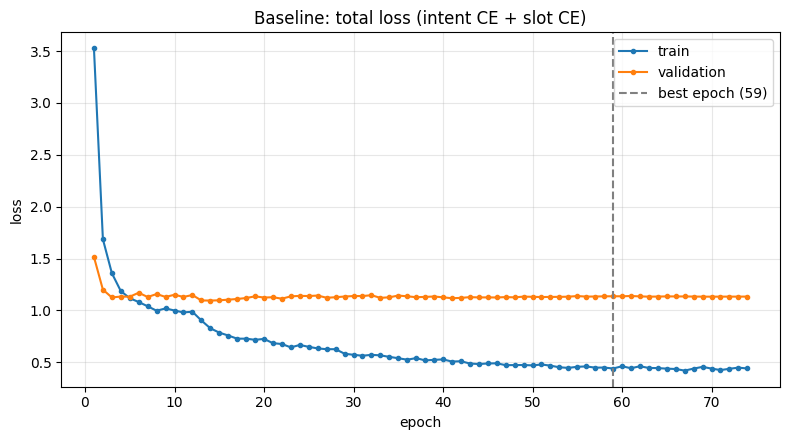

In [58]:
def get_history_values(history, key):
    """Pull one metric out of the per-epoch history as a list."""
    return [record[key] for record in history]


def plot_curve(history, series, title, ylabel, bestEpoch=None):
    """Plot one or more history metrics against epoch, optionally marking the best epoch.

    `series` is a list of (historyKey, legendLabel) pairs.
    """
    plt.figure(figsize=(8, 4.5))
    epochs = get_history_values(history, "epoch")

    for key, label in series:
        plt.plot(epochs, get_history_values(history, key), label=label, marker="o", markersize=3)

    if bestEpoch is not None:
        plt.axvline(bestEpoch, color="gray", linestyle="--", label=f"best epoch ({bestEpoch})")

    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_curve(
    baselineHistory,
    [("train_loss", "train"), ("val_loss", "validation")],
    "Baseline: total loss (intent CE + slot CE)",
    "loss",
    baselineBest["epoch"],
)

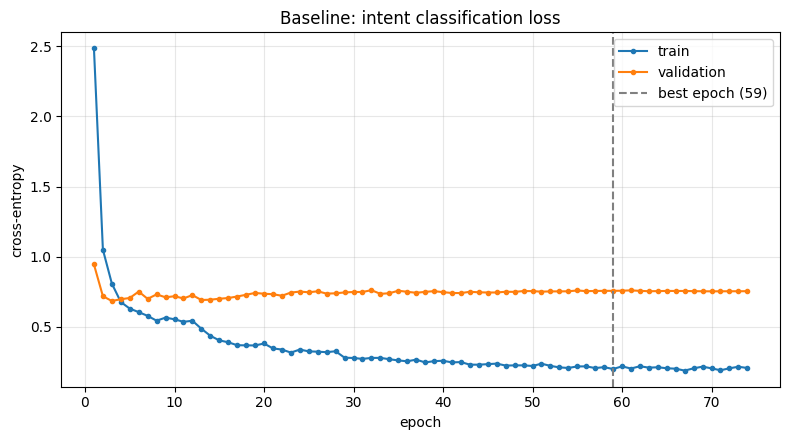

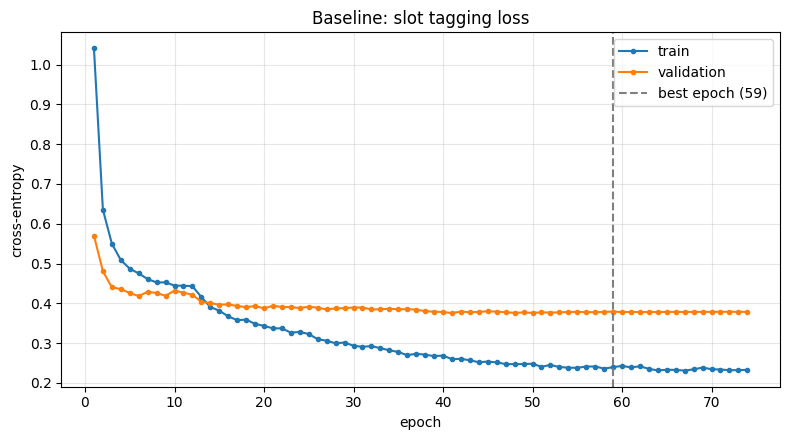

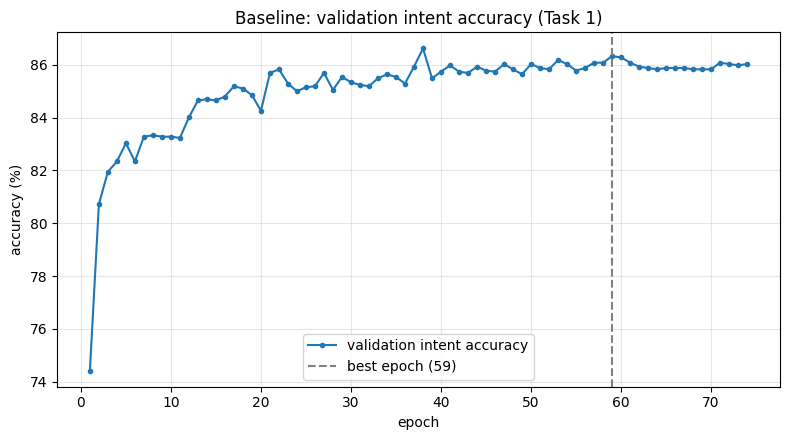

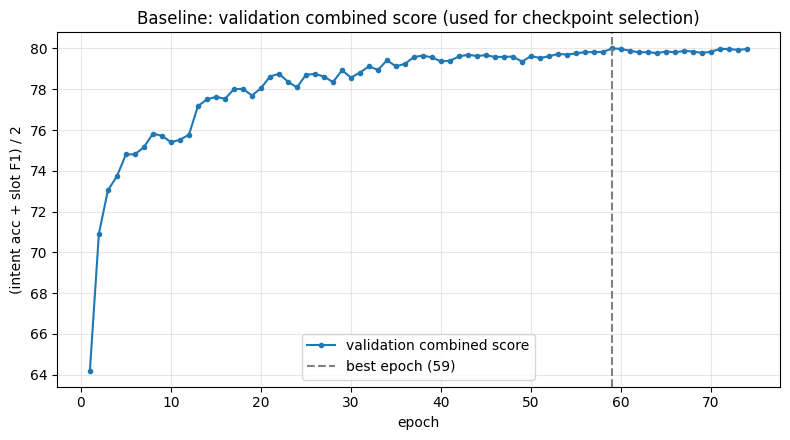

In [59]:
plot_curve(
    baselineHistory,
    [("train_intent_loss", "train"), ("val_intent_loss", "validation")],
    "Baseline: intent classification loss",
    "cross-entropy",
    baselineBest["epoch"],
)

plot_curve(
    baselineHistory,
    [("train_slot_loss", "train"), ("val_slot_loss", "validation")],
    "Baseline: slot tagging loss",
    "cross-entropy",
    baselineBest["epoch"],
)

plot_curve(
    baselineHistory,
    [("val_intent_acc", "validation intent accuracy")],
    "Baseline: validation intent accuracy (Task 1)",
    "accuracy (%)",
    baselineBest["epoch"],
)

plot_curve(
    baselineHistory,
    [("val_score", "validation combined score")],
    "Baseline: validation combined score (used for checkpoint selection)",
    "(intent acc + slot F1) / 2",
    baselineBest["epoch"],
)

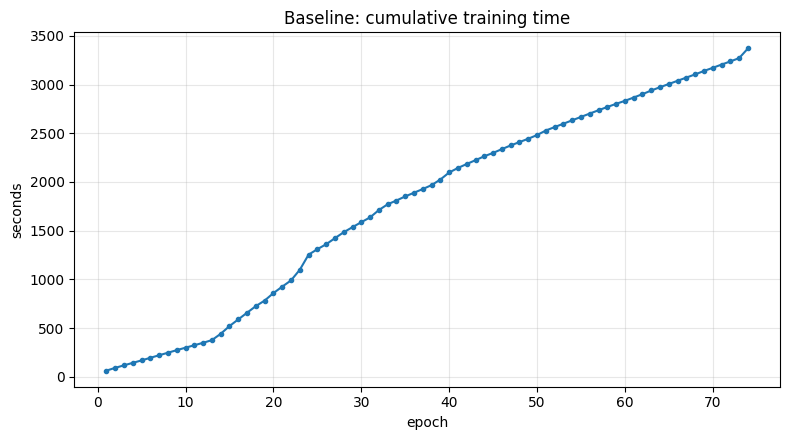

In [60]:
plt.figure(figsize=(8, 4.5))
plt.plot(get_history_values(baselineHistory, "epoch"),
         get_history_values(baselineHistory, "elapsed"),
         marker="o", markersize=3)
plt.title("Baseline: cumulative training time")
plt.xlabel("epoch")
plt.ylabel("seconds")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Final evaluation of the baseline checkpoint

The best checkpoint is loaded into a **freshly built** model (no further training) and evaluated on the validation and test splits. The validation scores must equal the best validation score recorded during training.

In [61]:
def final_evaluation(ckptPath, history, best, trainTime, label):
    model = build_baseline()
    checkpoint = torch.load(ckptPath, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    totalParams, trainableParams = count_params(model)
    print(f"loaded {ckptPath} (saved at epoch {checkpoint['epoch']})")

    valOut = predict(model, devLoader)
    valMetrics = score_split(valOut, encoded["dev"])
    testOut = predict(model, testLoader)
    testMetrics = score_split(testOut, encoded["test"])

    # validation score must reproduce the best score recorded during training
    assert abs(valMetrics["combined"] - best["score"]) < 0.01, (valMetrics, best)
    assert abs(valMetrics["intent_acc"] - best["metrics"]["intent_acc"]) < 0.01
    assert abs(valMetrics["slot_f1"] - best["metrics"]["slot_f1"]) < 0.01
    print("validation scores reproduce the best training-time score")

    print(f"\n{label} | total params {totalParams:,} | trainable {trainableParams:,} | "
          f"best epoch {checkpoint['epoch']} | epochs run {len(history)}")
    print(f"  VALIDATION  intent accuracy: {valMetrics['intent_acc']:.2f}% | slot micro-F1: {valMetrics['slot_f1']:.2f}%")
    print(f"  TEST        intent accuracy: {testMetrics['intent_acc']:.2f}% | slot micro-F1: {testMetrics['slot_f1']:.2f}%")

    results = {
        "label": label,
        "total_params": totalParams,
        "trainable_params": trainableParams,
        "best_epoch": checkpoint["epoch"],
        "epochs_run": len(history),
        "train_time_s": trainTime,
        "validation": {key: valMetrics[key] for key in ("intent_acc", "slot_f1")},
        "test": {key: testMetrics[key] for key in ("intent_acc", "slot_f1")},
    }
    return model, valOut, testOut, results


baselineModel, baseValOut, baseTestOut, baselineResults = final_evaluation(
    BASELINE_CKPT, baselineHistory, baselineBest, baselineTime, "Stage-1 BiLSTM baseline")

with open(os.path.join(SAVE_DIR, "baseline_results.json"), "w") as resultsFile:
    json.dump(baselineResults, resultsFile, indent=2)
with open(os.path.join(SAVE_DIR, "baseline_history.json"), "w") as historyFile:
    json.dump(baselineHistory, historyFile, indent=2)

loaded ../Results/baseline_bilstm_best.pt (saved at epoch 59)
validation scores reproduce the best training-time score

Stage-1 BiLSTM baseline | total params 2,499,001 | trainable 2,499,001 | best epoch 59 | epochs run 74
  VALIDATION  intent accuracy: 86.33% | slot micro-F1: 73.68%
  TEST        intent accuracy: 85.17% | slot micro-F1: 71.92%


In [62]:
# row format used in the report's comparison table
print(f"{'Model version':<16}{'Split':<12}{'#params':>12}{'#trainable':>12}{'Intent acc':>12}{'Slot F1':>10}{'Epochs':>8}")
for split in ("validation", "test"):
    metrics = baselineResults[split]
    print(f"{'Stage-1 system':<16}{split.capitalize():<12}"
          f"{baselineResults['total_params']:>12,}{baselineResults['trainable_params']:>12,}"
          f"{metrics['intent_acc']:>12.2f}{metrics['slot_f1']:>10.2f}{baselineResults['epochs_run']:>8}")

Model version   Split            #params  #trainable  Intent acc   Slot F1  Epochs
Stage-1 system  Validation     2,499,001   2,499,001       86.33     73.68      74
Stage-1 system  Test           2,499,001   2,499,001       85.17     71.92      74


### Baseline analysis (test split)

Per-task breakdowns to see where the BiLSTM fails: per-scenario intent accuracy, the most confused intent pairs, per-slot-type F1 and concrete error cases (useful for the report's error analysis).

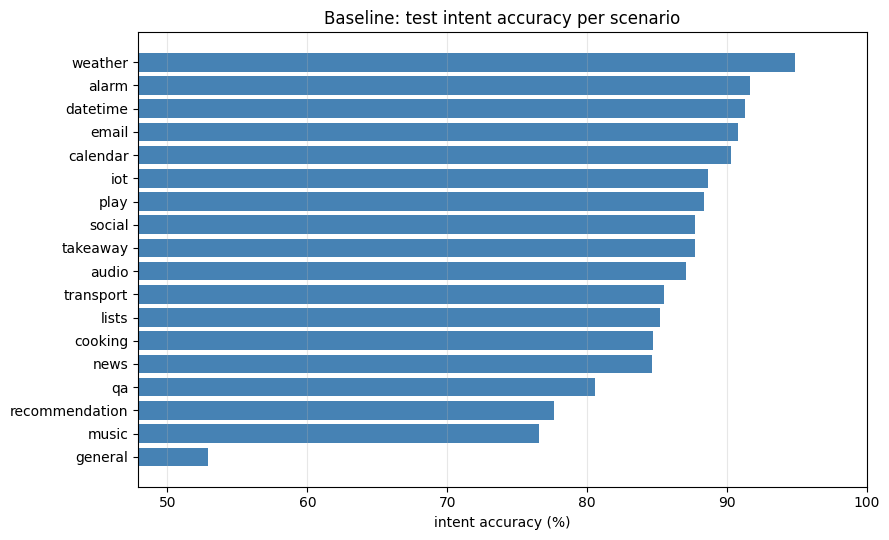

In [63]:
testGoldIntents = [idToIntent[example["intent"]] for example in encoded["test"]]
testPredIntents = baseTestOut["pred_intents"]
scenarioOf = {record["intent"]: record["scenario"] for split in splits.values() for record in split}

# per-scenario intent accuracy
scenarioCorrect, scenarioTotal = Counter(), Counter()
for goldIntent, predIntent in zip(testGoldIntents, testPredIntents):
    scenario = scenarioOf[goldIntent]
    scenarioTotal[scenario] += 1
    scenarioCorrect[scenario] += (goldIntent == predIntent)

scenarioAcc = {scenario: 100 * scenarioCorrect[scenario] / scenarioTotal[scenario] for scenario in scenarioTotal}
scenariosByAcc = sorted(scenarioAcc, key=scenarioAcc.get)

plt.figure(figsize=(9, 5.5))
plt.barh(scenariosByAcc, [scenarioAcc[scenario] for scenario in scenariosByAcc], color="steelblue")
plt.xlabel("intent accuracy (%)")
plt.title("Baseline: test intent accuracy per scenario")
plt.xlim(min(scenarioAcc.values()) - 5, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

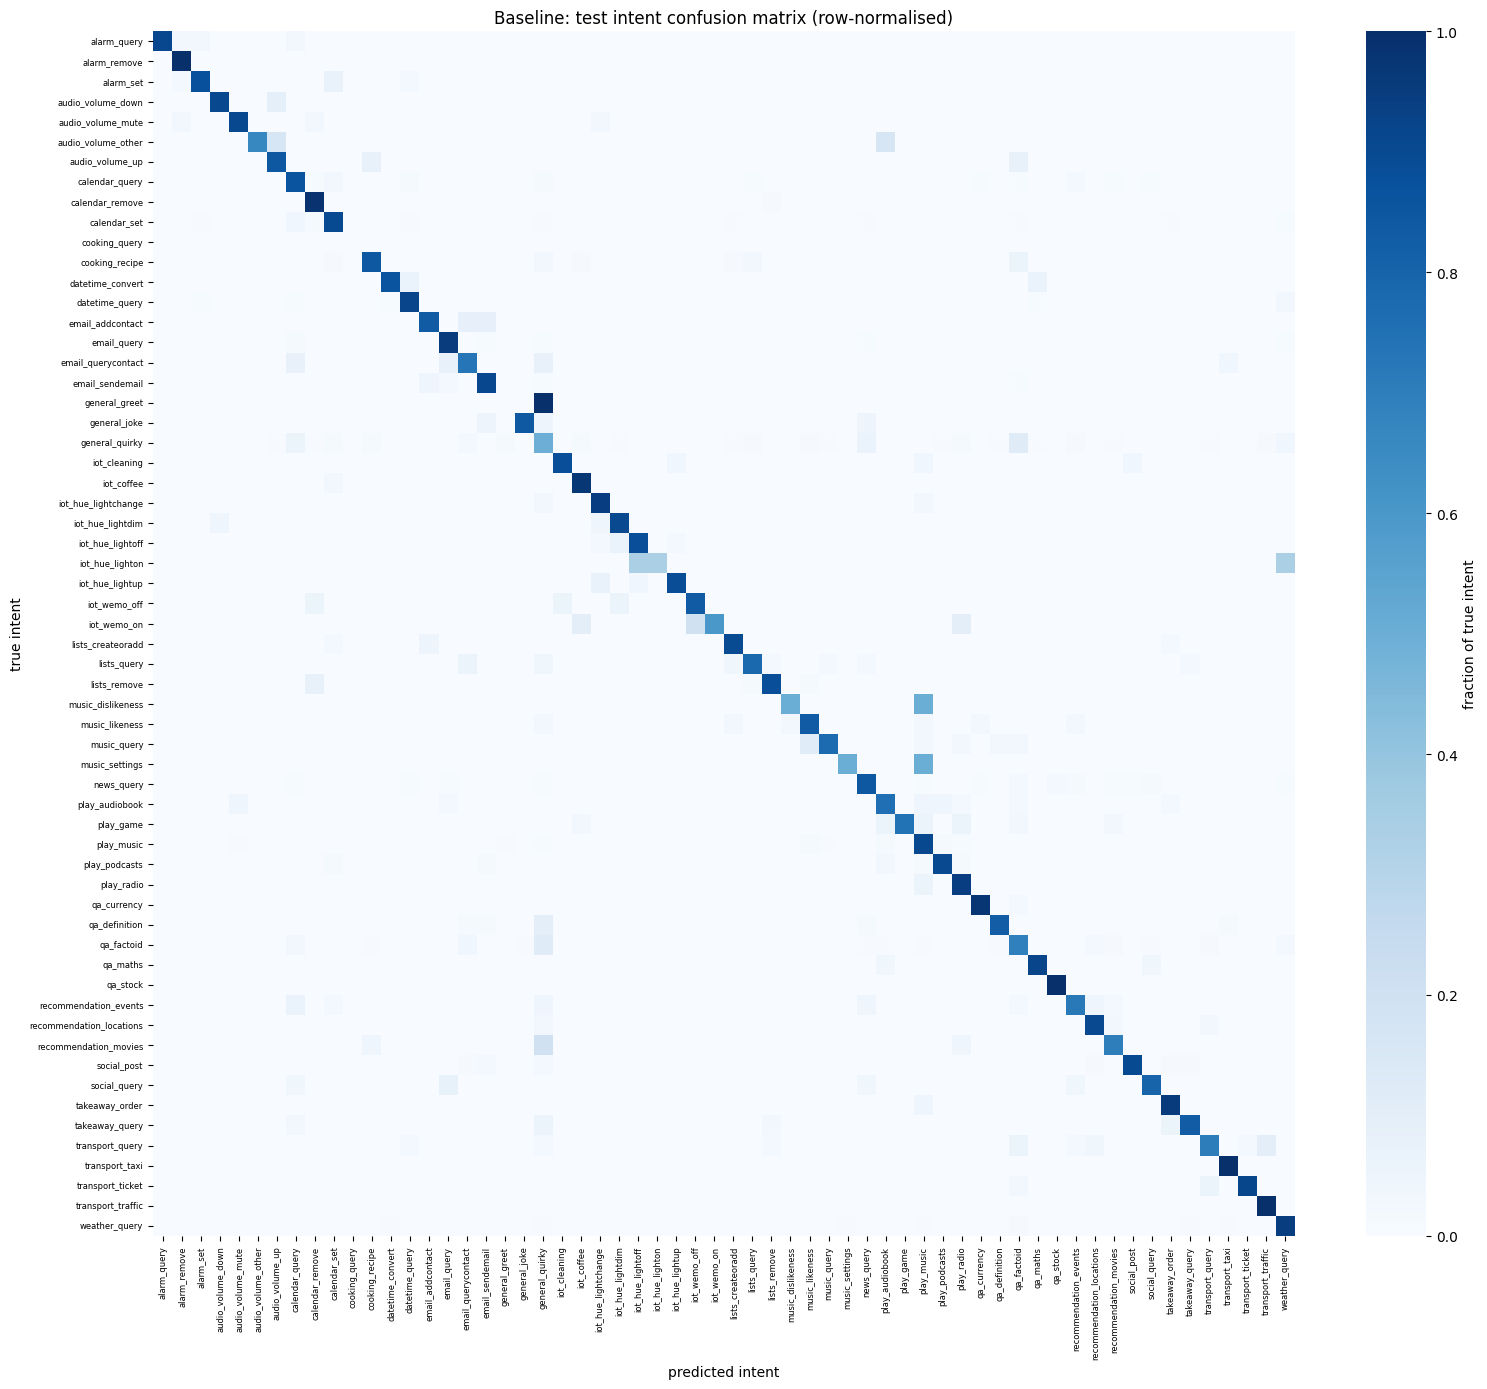

most confused intent pairs (count, true -> predicted):
   21  general_quirky  ->  qa_factoid
   17  qa_factoid  ->  general_quirky
   11  general_quirky  ->  news_query
   10  general_quirky  ->  calendar_query
    8  calendar_set  ->  calendar_query
    6  qa_definition  ->  general_quirky
    6  general_quirky  ->  weather_query
    5  transport_query  ->  transport_traffic
    5  qa_factoid  ->  email_querycontact
    5  email_sendemail  ->  email_addcontact
    4  recommendation_movies  ->  general_quirky
    4  qa_factoid  ->  calendar_query


In [64]:
# confusion matrix over the 60 intents (row-normalised)
numIntents = len(intents)
confusionCounts = np.zeros((numIntents, numIntents), dtype=int)
for goldIntent, predIntent in zip(testGoldIntents, testPredIntents):
    confusionCounts[intentToId[goldIntent], intentToId[predIntent]] += 1
confusionNorm = confusionCounts / confusionCounts.sum(axis=1, keepdims=True).clip(min=1)

plt.figure(figsize=(16, 14))
sns.heatmap(confusionNorm, 
            xticklabels=intents, 
            yticklabels=intents, 
            cmap="Blues", 
            vmin=0, vmax=1,
            cbar_kws={"label": "fraction of true intent"}
            )

plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6)
plt.xlabel("predicted intent")
plt.ylabel("true intent")
plt.title("Baseline: test intent confusion matrix (row-normalised)")
plt.tight_layout()
plt.show()

# top confused pairs
offDiagonal = [
    (confusionCounts[i, j], intents[i], intents[j])
    for i in range(numIntents)
    for j in range(numIntents)
    if i != j and confusionCounts[i, j] > 0
]
print("most confused intent pairs (count, true -> predicted):")
for count, trueIntent, predIntent in sorted(offDiagonal, reverse=True)[:12]:
    print(f"  {count:3d}  {trueIntent}  ->  {predIntent}")

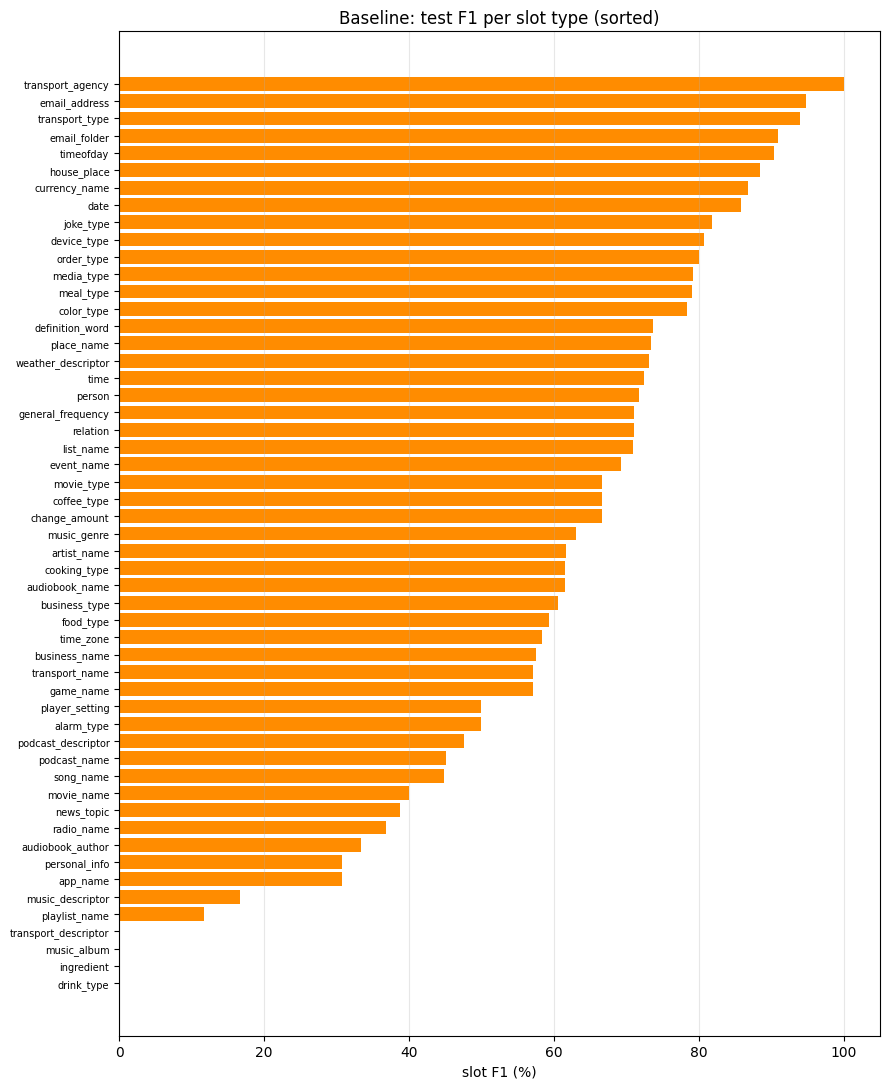

weakest slot types (type, F1, #gold in test):
  drink_type              0.00  n=1
  ingredient              0.00  n=6
  music_album             0.00  n=1
  transport_descriptor    0.00  n=2
  playlist_name          11.76  n=16
  music_descriptor       16.67  n=7
  app_name               30.77  n=5
  personal_info          30.77  n=14
  audiobook_author       33.33  n=5
  radio_name             36.84  n=33


In [65]:
# per-slot-type F1 on test
def per_type_scores(goldAll, predAll):
    truePos, falsePos, falseNeg = Counter(), Counter(), Counter()

    for goldSlots, predSlots in zip(goldAll, predAll):
        goldCounts, predCounts = Counter(goldSlots), Counter(predSlots)
        matched = goldCounts & predCounts

        for (slotType, _), count in matched.items():
            truePos[slotType] += count
        for (slotType, _), count in (predCounts - matched).items():
            falsePos[slotType] += count
        for (slotType, _), count in (goldCounts - matched).items():
            falseNeg[slotType] += count

    rows = []
    for slotType in sorted(set(truePos) | set(falsePos) | set(falseNeg)):
        denominator = 2 * truePos[slotType] + falsePos[slotType] + falseNeg[slotType]
        f1 = 100 * 2 * truePos[slotType] / denominator if denominator else 0.0
        numGold = truePos[slotType] + falseNeg[slotType]
        rows.append((slotType, f1, numGold))
    return rows


testGoldSlots = [example["gold_slots"] for example in encoded["test"]]
slotRows = per_type_scores(testGoldSlots, baseTestOut["pred_slots"])
slotRows.sort(key=lambda row: row[1])

plt.figure(figsize=(9, 11))
plt.barh([row[0] for row in slotRows], [row[1] for row in slotRows], color="darkorange")
plt.xlabel("slot F1 (%)")
plt.title("Baseline: test F1 per slot type (sorted)")
plt.yticks(fontsize=7)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("weakest slot types (type, F1, #gold in test):")
for slotType, f1, numGold in slotRows[:10]:
    print(f"  {slotType:<22}{f1:6.2f}  n={numGold}")

In [66]:
# concrete error cases (random sample, fixed seed)
rng = random.Random(SEED)
test_records = splits["test"]

intent_err = [i for i, (g_, p_) in enumerate(zip(testGoldIntents, testPredIntents)) if g_ != p_]
slot_err = [i for i in range(len(test_records))
            if Counter(testGoldSlots[i]) != Counter(baseTestOut["pred_slots"][i])
            ]

print(f"test intent errors: {len(intent_err)}/{len(test_records)} | test utterances with >=1 slot error: {len(slot_err)}/{len(test_records)}\n")

print("intent errors")
for i in rng.sample(intent_err, min(6, len(intent_err))):
    print(f"utt: {test_records[i]['utt']}\n  gold: {testGoldIntents[i]} | pred: {testPredIntents[i]}")

print("\nslot errors")
for i in rng.sample(slot_err, min(6, len(slot_err))):
    print(f"utt: {test_records[i]['utt']}\n  gold: {testGoldSlots[i]}\n  pred: {baseTestOut['pred_slots'][i]}")

test intent errors: 441/2974 | test utterances with >=1 slot error: 909/2974

intent errors
utt: tell me if global warming is true
  gold: general_quirky | pred: weather_query
utt: web searches
  gold: general_quirky | pred: qa_factoid
utt: tell me the info about india's geography
  gold: qa_factoid | pred: news_query
utt: please play clash of clans
  gold: play_game | pred: play_music
utt: play for me the game harry potter and the chamber of secrets
  gold: play_game | pred: play_audiobook
utt: this new email should be added to my contact
  gold: email_sendemail | pred: email_addcontact

slot errors
utt: order a twelve piece honey mustard wing combo with seasonimg altnon the fries and a sprite as the drink
  gold: [('food_type', 'honey mustard wing combo'), ('drink_type', 'sprite')]
  pred: [('food_type', 'honey mustard wing'), ('food_type', 'combo with seasonimg altnon the fries'), ('food_type', 'and'), ('food_type', 'as')]
utt: set a reminder about todays faculty meeting at four
  g

---
*Stage 2 (AI-enhanced system) goes below this line. `train_model`, `predict`, `score_split` and `final_evaluation` take the model/checkpoint as arguments so they can be reused with the same scoring rules.*